In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
sns.set_style ("whitegrid")

In [7]:
df = pd.read_csv('/content/healthcare-dataset-stroke-data.csv')

In [8]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [10]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


/tmp/ipykernel_358/615027696.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.countplot(data=df,x='stroke',palette='Set2')


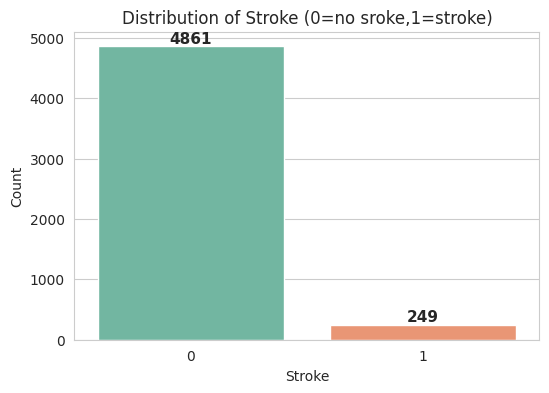

In [11]:
plt.figure(figsize=(6,4))
ax=sns.countplot(data=df,x='stroke',palette='Set2')
plt.title('Distribution of Stroke (0=no sroke,1=stroke)')
plt.xlabel('Stroke')
plt.ylabel('Count')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.show()




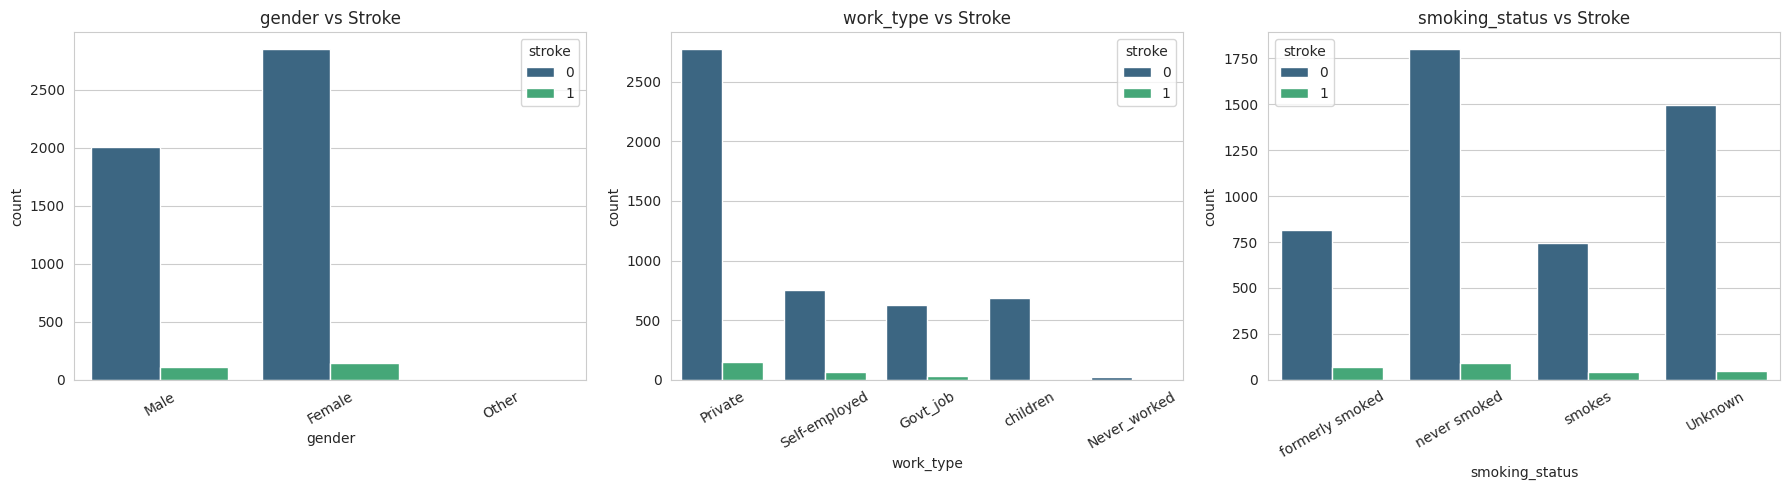

In [12]:
df=df[df['gender']!='others']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
categorical_cols = ['gender', 'work_type', 'smoking_status']

for i, col in enumerate(categorical_cols):
    sns.countplot(data=df, x=col, hue='stroke', ax=axes[i], palette='viridis')
    axes[i].set_title(f'{col} vs Stroke')
    axes[i].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()



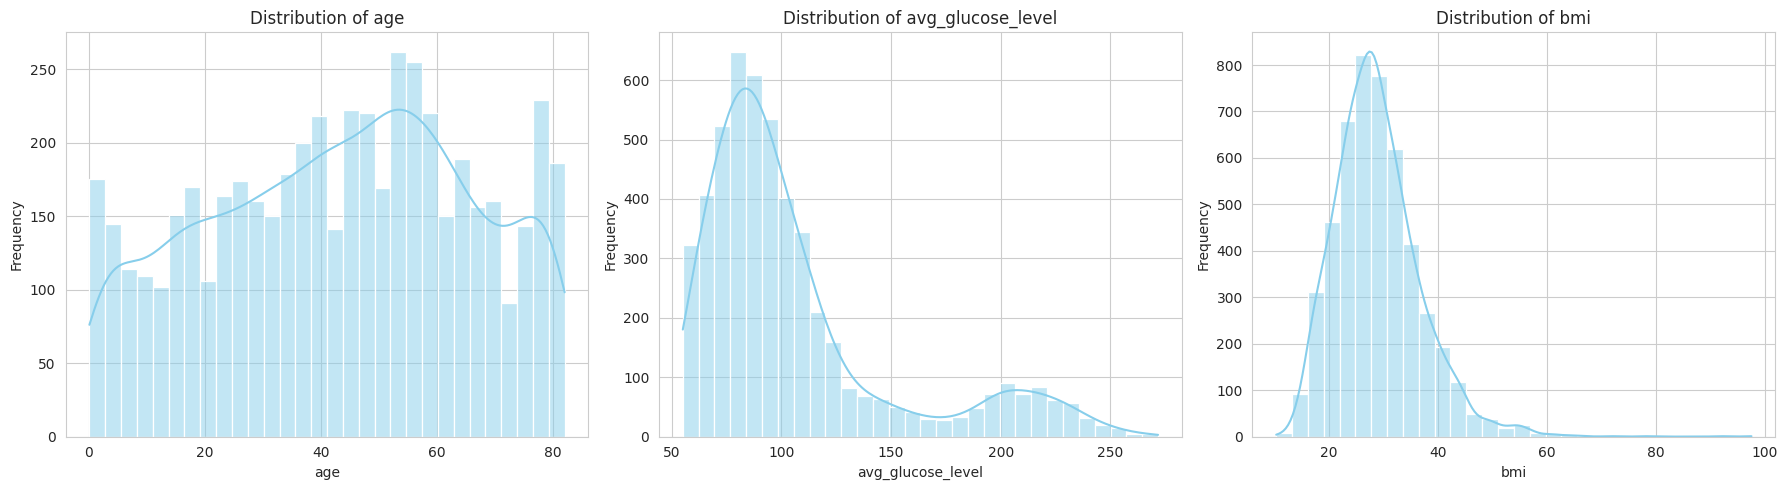

In [13]:
from numpy._core import numeric
fig,axes=plt.subplots(1,3,figsize=(18,5))
numeric_cols=['age','avg_glucose_level','bmi']
for i,col in enumerate(numeric_cols):
  sns.histplot(data=df,x=col,kde=True, ax=axes[i],color='skyblue',bins=30)
  axes[i].set_title(f'Distribution of {col}')
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('Frequency')
plt.tight_layout()
plt.show()




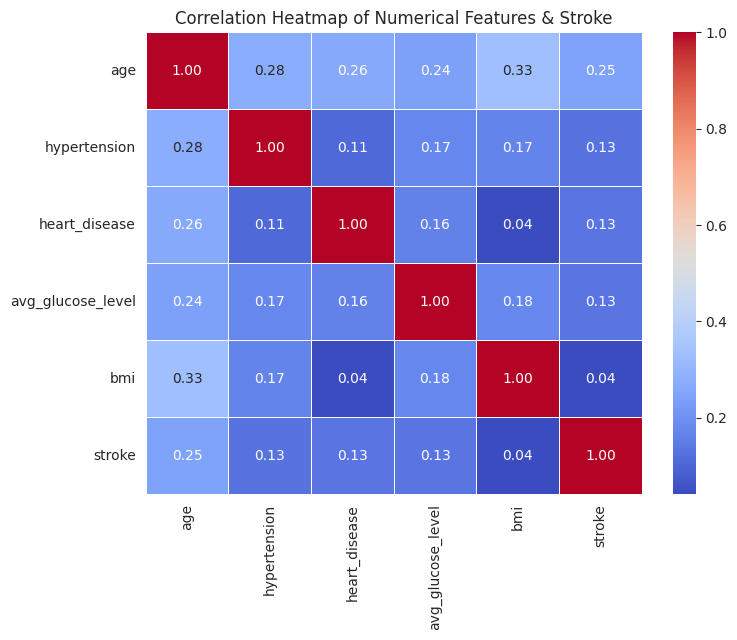

In [14]:
plt.figure(figsize=(8,6))
corr_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']
corr_matrix = df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features & Stroke')
plt.show()

In [15]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [16]:
df['bmi']=df['bmi'].fillna(df['bmi'].mean())
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0


In [17]:
duplicates_count = df.duplicated().sum()
df = df.drop_duplicates()

In [18]:
df=df.drop(columns=['id'])

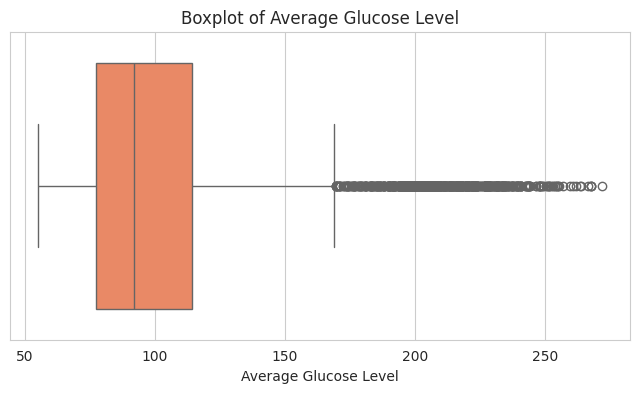

In [19]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['avg_glucose_level'], color='coral')
plt.title('Boxplot of Average Glucose Level')
plt.xlabel('Average Glucose Level')
plt.show()

In [20]:
categorical_features = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
df=df.reset_index(drop=True)

In [21]:
df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=True, dtype=int)

In [22]:
display(df_encoded.head())

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.600000,1,1,0,1,0,1,0,0,1,1,0,0
1,61.0,0,0,202.21,28.893237,1,0,0,1,0,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.500000,1,1,0,1,0,1,0,0,0,0,1,0
3,49.0,0,0,171.23,34.400000,1,0,0,1,0,1,0,0,1,0,0,1
4,79.0,1,0,174.12,24.000000,1,0,0,1,0,0,1,0,0,0,1,0


In [23]:
from sklearn.model_selection import train_test_split


In [24]:
x=df_encoded.drop(columns=['stroke'])
y=df_encoded['stroke']
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(4088, 16)
(1022, 16)
(4088,)
(1022,)


In [25]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
num_cols=['age','avg_glucose_level','bmi']
X_train[num_cols]=scaler.fit_transform(X_train[num_cols])
X_test[num_cols]=scaler.transform(X_test[num_cols])

X_train.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
845,0.205661,0,0,-0.819973,0.538479,0,0,1,0,1,0,0,1,0,1,0
3744,-1.254901,0,0,0.352075,-1.020641,1,0,0,0,1,0,0,0,0,1,0
4183,1.046590,0,0,0.090662,-0.518114,0,0,1,0,0,1,0,0,0,1,0
3409,0.028623,0,0,-0.903944,-0.531000,1,0,1,0,1,0,0,1,0,0,1
284,-1.299160,0,0,-0.529834,0.345200,1,0,0,0,0,0,0,1,0,0,0


In [26]:
print(X_train[['age', 'avg_glucose_level', 'bmi']].describe().round(2))

           age  avg_glucose_level      bmi
count  4088.00            4088.00  4088.00
mean     -0.00               0.00     0.00
std       1.00               1.00     1.00
min      -1.92              -1.13    -2.40
25%      -0.77              -0.64    -0.66
50%       0.07              -0.32    -0.07
75%       0.78               0.17     0.50
max       1.71               3.66     8.85


In [27]:

from imblearn.over_sampling import SMOTE
print(y_train.value_counts())
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print(y_train_balanced.value_counts())

stroke
0    3889
1     199
Name: count, dtype: int64
stroke
0    3889
1    3889
Name: count, dtype: int64
